In [1]:
from functools import partial

from tqdm import tqdm
import matplotlib
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

import torch
from torch import from_numpy, no_grad, repeat_interleave
import numpy as np
import optuna
import mlflow

from ml.data import QuantumJumpDataset
from ml.tune import objective
from ml.types import LossType, ModelType
from ml.loss import RMSELoss

# Set matplotlib to use TeX for rendering
matplotlib.rcParams.update({"font.size": 16}) 
plt.rcParams["figure.dpi"] = 125 # set fig resolution

plt.rcParams.update({"text.usetex": True, "font.family": "Helvetica"})

/home/amanuelant/.local/lib/python3.10/site-packages/pymc_marketing/mlflow.py:185: FutureWarning: This functionality is experimental and subject to change. If you encounter any issues or have suggestions, please raise them at: https://github.com/pymc-labs/pymc-marketing/issues/new
  warnings.warn(warning_msg, FutureWarning, stacklevel=1)
/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/pyfunc/utils/data_validation.py:186: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


Dataset `train_val_data/estimation_data/train/2D/taus.npy` contains $3,200,000$ ($80\%$ of the original training data from the paper) trajectories of length $T=48$ and `deltas_omegas.npy` contains $3,200,000$ the associated detuning and Rabi frequency parameters $\Delta$ and $\Omega$, respectively, for each trajectory.

In [2]:
fraction = 0.01 #config["data"]["fraction"]

train_set_size = int(3_200_000 * fraction)
val_set_size = int(800_000 * fraction)


X_train = np.load("../train_val_data/estimation_data/train/2D/taus.npy")[
    :train_set_size
]

y_train = np.load("../train_val_data/estimation_data/train/2D/deltas_omegas.npy")[:train_set_size]

X_val = np.load("../train_val_data/estimation_data/val/2D/taus.npy")[:val_set_size]

y_val = np.load("../train_val_data/estimation_data/val/2D/deltas_omegas.npy")[:val_set_size]


print(f"Shape of train data: {X_train.shape}.")
print(f"Shape of train labels: {y_train.shape}.")

print(f"Shape of val data: {X_val.shape}.")
print(f"Shape of val labels: {y_val.shape}.")


train_dataset = QuantumJumpDataset(
    X_train,
    y_train,
    feature_noise_std=0,
    label_noise_std=0,
    seed=22
)
val_dataset = QuantumJumpDataset(
    X_val,
    y_val,
    feature_noise_std=0,
    label_noise_std=0,
    seed=22
)

Shape of train data: (32000, 48).
Shape of train labels: (32000, 2).
Shape of val data: (8000, 48).
Shape of val labels: (8000, 2).


In [ ]:
# data = [train_dataset.labels.numpy().flatten(), val_dataset.labels.numpy().flatten()]
# plt.boxplot(data, tick_labels=[f"Train $\Delta$'s", f"Validation $\Delta$'s"])
# plt.ylabel(r"$\Delta/\gamma$")
# plt.title("Boxplot of $\Delta$'s in the training and validation sets");

In [ ]:
# data = [train_dataset.labels.numpy().flatten(), val_dataset.labels.numpy().flatten()]
# plt.hist(data[0], bins=300, alpha=0.7, label=f"Train $\Delta$'s", color="skyblue")
# plt.hist(data[1], bins=300, alpha=0.7, label=f"Validation $\Delta$'s", color="salmon")
# plt.xlabel(r"$\Delta/\gamma$")
# plt.ylabel("Counts")
# plt.legend()
# plt.title("Histogram of $\Delta$'s in the training and validation sets");

In [5]:
model_cls, trainer_cls = ModelType["hist"].value

In [ ]:
device = 'cuda'
objective_metric = "rmse"
hidden_layer_sizes = [100, 50, 30, 20, 10]
epochs_per_val = 2
n_trials = 20


partial_objective_fn = partial(
    objective,
    model_cls=model_cls,
    trainer_cls=trainer_cls,
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    device=device,
    objective_metric=objective_metric,
    epochs_per_val=epochs_per_val,
    hidden_layer_sizes=hidden_layer_sizes
)


mlflow.set_experiment("Single Networks - 2D")

Traceback (most recent call last):
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 356, in search_experiments
    exp = self._get_experiment(exp_id, view_type)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 454, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 1595, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 1588, in _read_helper
    result = read_yaml(root, file_name)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/utils/yaml_utils.py", line 107, in read_yaml
    raise MissingConfigException(f"Yaml file '{file_path}' does not exist.")
mlflow.exceptions.MissingCon

<Experiment: artifact_location='file:///home/amanuelant/ensemble-param-est/mlruns/371879113660947979', creation_time=1766615148144, experiment_id='371879113660947979', last_update_time=1766615148144, lifecycle_stage='active', name='Single Networks - 2D Estimation', tags={}>

In [ ]:
with mlflow.start_run() as parent_run:
    mlflow.log_param("fraction", fraction)


    mlflow.log_param("epochs_per_val", epochs_per_val)

    obj_metric = objective_metric
    lower_is_better = LossType[obj_metric].value[1]

    study = optuna.create_study(
        direction="minimize" if lower_is_better else "maximize",
        pruner=optuna.pruners.MedianPruner(n_startup_trials=10),
    )

    study.optimize(partial_objective_fn, n_trials=n_trials)

    best_trial = study.best_trial
    best_model_uri = f"runs:/{best_trial.user_attrs['run_id']}/torch_model"

    # Log best child run's parameters and objective metric to the parent run
    mlflow.log_params(best_trial.params)
    mlflow.log_param("best_trial_number", best_trial.number)
    mlflow.log_param("best_model_uri", best_model_uri)
    mlflow.log_param("best_model_run_name", best_trial.user_attrs["run_name"])
    mlflow.log_metric(f"best_{objective_metric}", best_trial.value)

    device = device

    selected_model = mlflow.pytorch.load_model(model_uri=best_model_uri)
    # if model was logged while on gpu it will be loaded back onto gpu and will error out if GPU is not available
    selected_model = selected_model.to(device)

    X_test = np.load("../test-trajectories/2D-delta-omega/validation-trajectories-2D-delta-omega-nsets-10000.npy", mmap_mode="r")
    y_test = np.load("../test-trajectories/2D-delta-omega/validation-deltas-2D-delta-omega-nsets-10000.npy")

    selected_model.eval()
    rmse_loss = RMSELoss()

    with no_grad():
        rmses = []
        error_fn = RMSELoss()
        # loop over all 1,600 detuning-rabi freq pairs
        for i in tqdm(range(1600)):
            num_trajs = 1000
            batch_of_trajs = torch.tensor(X_test[i][:num_trajs]).to(device=device, dtype=torch.float32)
            batch_output = selected_model(batch_of_trajs)
            label = torch.tensor(y_test[i]).to(device=device, dtype=torch.float32)
            repeated_labels = repeat_interleave(label, repeats=batch_output.shape[0]).reshape(-1, 2)
            error = error_fn(batch_output, repeated_labels)
            rmses.append(error.cpu().numpy())
    


    x = np.sort(np.unique(y_test[:, 0])) # x axis is delta  #np.linspace(-3, 3, 200)
    y = np.sort(np.unique(y_test[:, 1])) # y axis is omega #np.linspace(-3, 3, 200)
    X, Y = np.meshgrid(x, y)
    Z = np.array(rmses).reshape(40,40) # there are 40x40=1,600 labels (detuning-rabi freq pairs)
    Z = gaussian_filter(Z, sigma=2)

    plt.figure()
    cs = plt.contourf(
        X, Y, Z,
        levels=30,
        cmap=plt.get_cmap('BuPu').reversed(),
        # vmax=0.4,
        # vmin=0.1
    )
    plt.colorbar(cs, label=r"$\textrm{RMSE}(\hat{\Delta}, \hat{\Omega})/\gamma$")
    plt.xlabel(r"$\Delta/\gamma$")
    plt.ylabel(r"$\Omega/\gamma$")
    fig = plt.gcf()
    mlflow.log_figure(fig, "rmses.png")
    plt.show()


mlflow.end_run()

[I 2025-12-25 09:43:43,598] A new study created in memory with name: no-name-571db8dd-f542-4224-a943-a058920c7df7
[I 2025-12-25 09:45:14,604] Trial 0 finished with value: 0.00012850189208984375 and parameters: {'num_bins': 580, 'training_loss_function': 'rmse', 'lr': 8.913743556407226e-05, 'beta1': 0.803047478601247, 'beta2': 0.8192643981896817, 'num_epochs': 140, 'batch_size': 2048, 'dropout': 0.15000000000000002, 'patience': 7}. Best is trial 0 with value: 0.00012850189208984375.
[I 2025-12-25 09:48:17,664] Trial 1 finished with value: 6.55171275138855e-05 and parameters: {'num_bins': 560, 'training_loss_function': 'rmse', 'lr': 0.0003686319055692456, 'beta1': 0.9197936679103987, 'beta2': 0.9401990138560408, 'num_epochs': 260, 'batch_size': 1024, 'dropout': 0.15000000000000002, 'patience': 10}. Best is trial 1 with value: 6.55171275138855e-05.
[I 2025-12-25 09:49:55,318] Trial 2 finished with value: 8.471109718084335e-05 and parameters: {'num_bins': 370, 'training_loss_function': 'rm

Stopping early at epoch 158/196


[I 2025-12-25 10:00:53,315] Trial 3 finished with value: 5.602629110217094e-05 and parameters: {'num_bins': 670, 'training_loss_function': 'rmse', 'lr': 0.0002509144472733584, 'beta1': 0.9241789888345164, 'beta2': 0.9541330902745133, 'num_epochs': 195, 'batch_size': 64, 'dropout': 0.05, 'patience': 10}. Best is trial 3 with value: 5.602629110217094e-05.
[I 2025-12-25 10:02:47,024] Trial 4 finished with value: 6.252223998308182e-05 and parameters: {'num_bins': 330, 'training_loss_function': 'rmse', 'lr': 0.0003599175272933298, 'beta1': 0.8999112253812683, 'beta2': 0.9097610754231018, 'num_epochs': 140, 'batch_size': 512, 'dropout': 0.05, 'patience': 10}. Best is trial 3 with value: 5.602629110217094e-05.
[I 2025-12-25 10:04:12,962] Trial 5 finished with value: 0.00013599054515361786 and parameters: {'num_bins': 370, 'training_loss_function': 'msle', 'lr': 2.6077087277209868e-05, 'beta1': 0.8644942199653652, 'beta2': 0.9918758944835412, 'num_epochs': 100, 'batch_size': 512, 'dropout': 0.

Stopping early at epoch 8/166


[I 2025-12-25 10:04:24,722] Trial 6 finished with value: 0.0003142130970954895 and parameters: {'num_bins': 390, 'training_loss_function': 'msle', 'lr': 0.0011186023844029702, 'beta1': 0.8400314071736231, 'beta2': 0.8765544956973288, 'num_epochs': 165, 'batch_size': 512, 'dropout': 0.0, 'patience': 7}. Best is trial 3 with value: 5.602629110217094e-05.


...

[I 2025-12-25 10:35:07,174] Trial 16 finished with value: 5.663833022117615e-05 and parameters: {'num_bins': 640, 'training_loss_function': 'rmse', 'lr': 0.0005986319093017777, 'beta1': 0.8833953419474894, 'beta2': 0.8811258759562824, 'num_epochs': 185, 'batch_size': 128, 'dropout': 0.0, 'patience': 6}. Best is trial 3 with value: 5.602629110217094e-05.
[I 2025-12-25 10:35:08,468] Trial 17 pruned. 
[I 2025-12-25 10:35:08,990] Trial 18 pruned. 


Stopping early at epoch 121/166


[I 2025-12-25 10:43:14,946] Trial 19 finished with value: 5.670088157057762e-05 and parameters: {'num_bins': 650, 'training_loss_function': 'rmse', 'lr': 0.00021367829865307896, 'beta1': 0.84600372389843, 'beta2': 0.9576754230466049, 'num_epochs': 165, 'batch_size': 64, 'dropout': 0.1, 'patience': 6}. Best is trial 3 with value: 5.602629110217094e-05.


  8%|▊         | 131/1600 [02:07<23:52,  1.03it/s]


KeyboardInterrupt: 

100%|██████████| 1600/1600 [00:07<00:00, 212.88it/s]


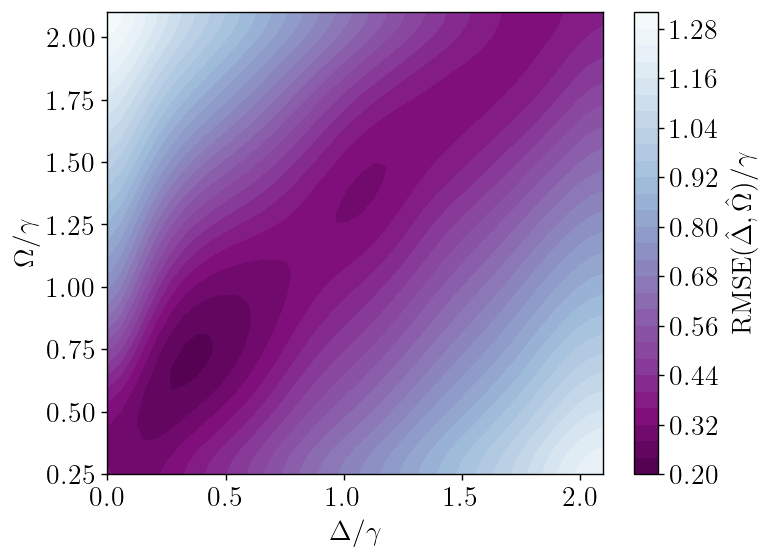

100%|██████████| 1600/1600 [00:08<00:00, 193.78it/s]


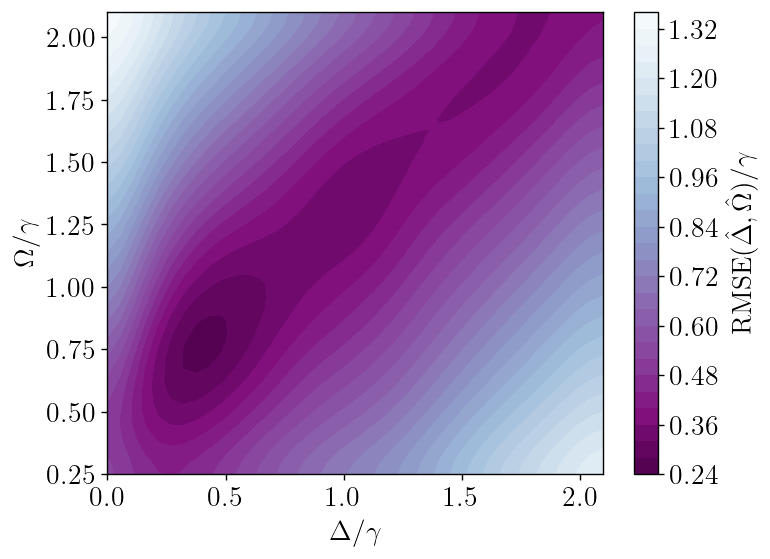

100%|██████████| 1600/1600 [00:10<00:00, 157.11it/s]


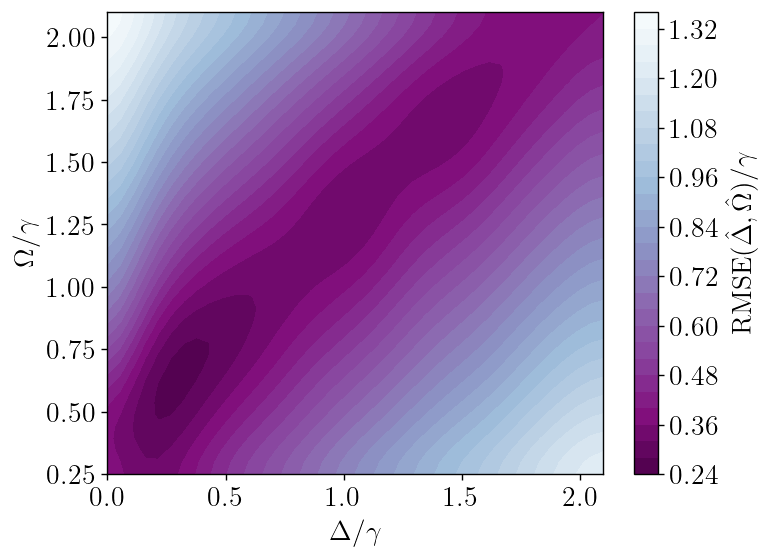

100%|██████████| 1600/1600 [00:05<00:00, 300.24it/s]


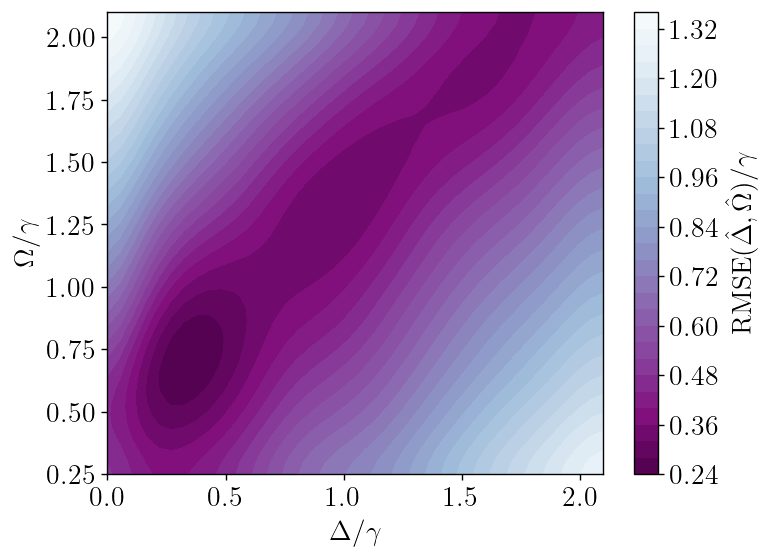

100%|██████████| 1600/1600 [00:07<00:00, 205.39it/s]


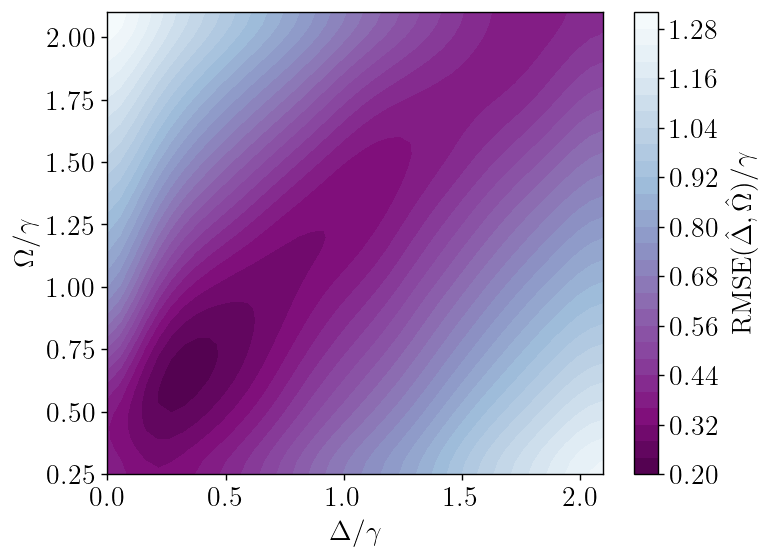

100%|██████████| 1600/1600 [00:03<00:00, 461.06it/s]


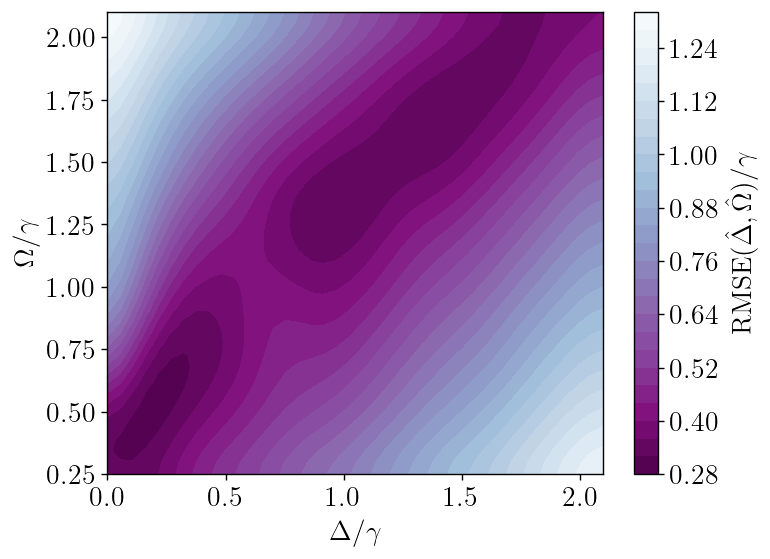

100%|██████████| 1600/1600 [00:08<00:00, 183.84it/s]


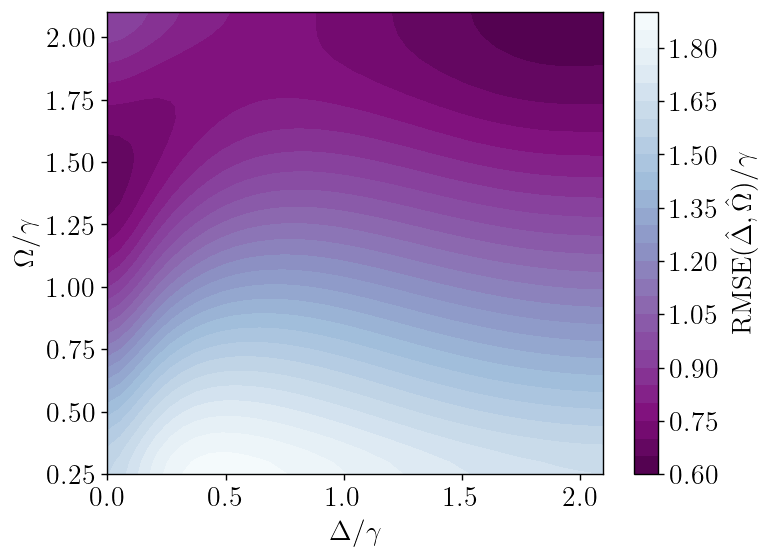

100%|██████████| 1600/1600 [00:11<00:00, 144.62it/s]


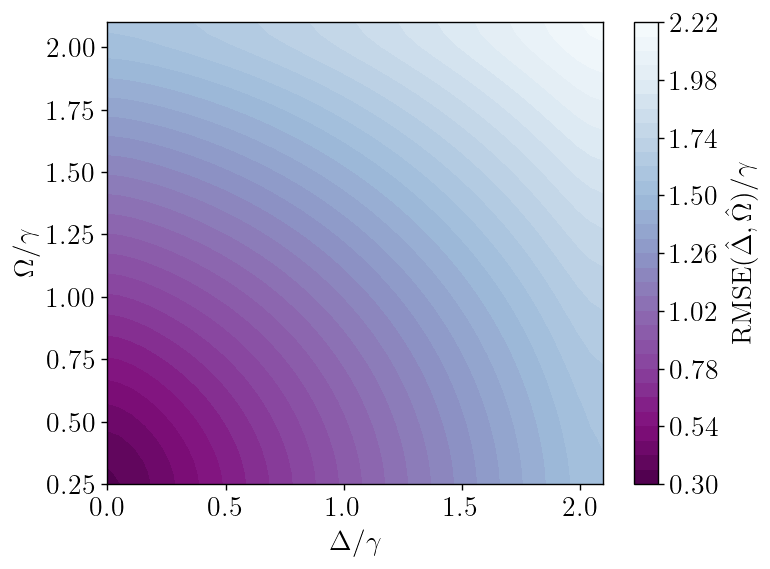

100%|██████████| 1600/1600 [00:06<00:00, 235.78it/s]


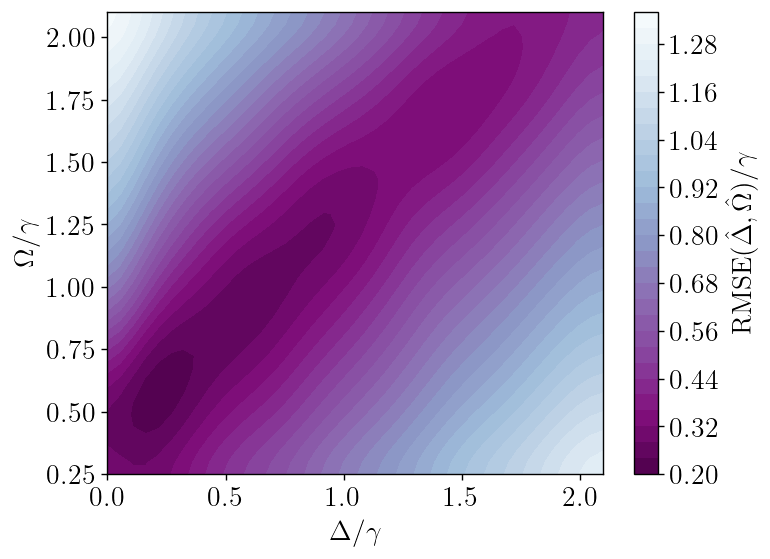

100%|██████████| 1600/1600 [00:10<00:00, 155.89it/s]


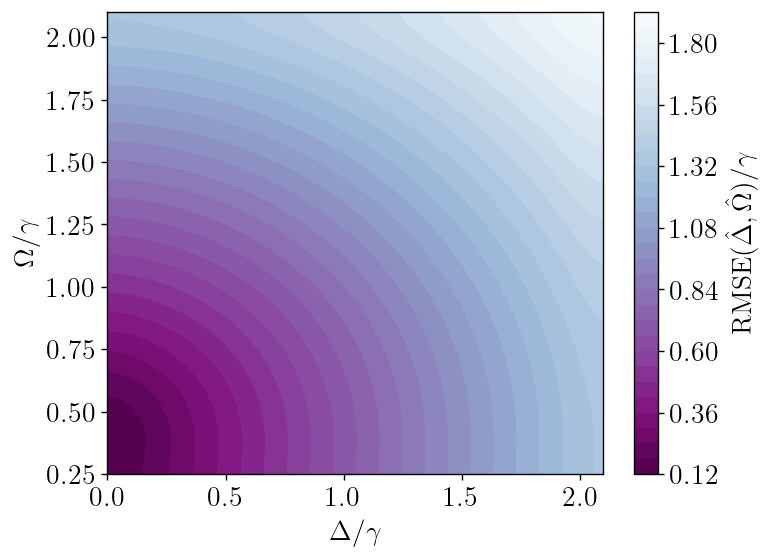

100%|██████████| 1600/1600 [00:11<00:00, 144.27it/s]


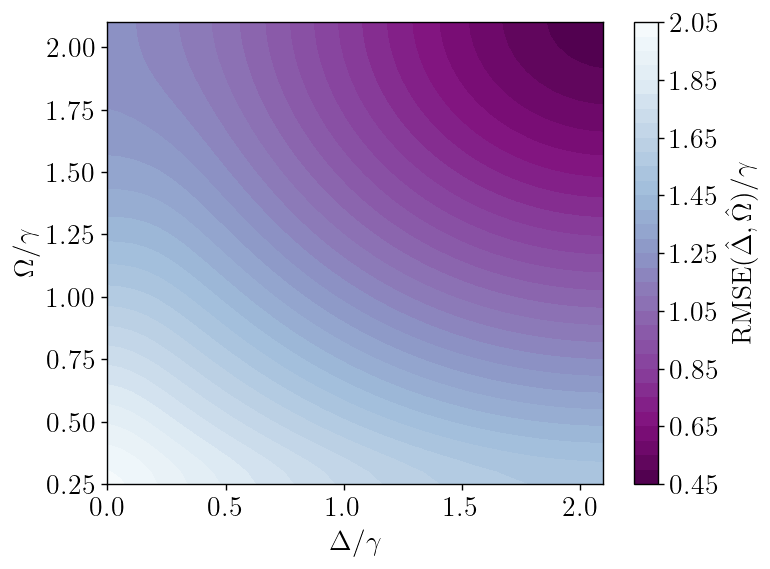

100%|██████████| 1600/1600 [00:10<00:00, 153.02it/s]


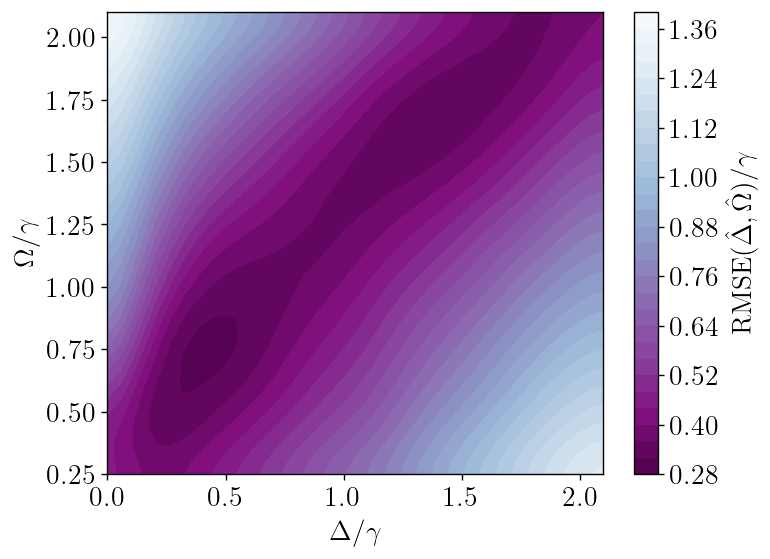

100%|██████████| 1600/1600 [00:08<00:00, 185.75it/s]


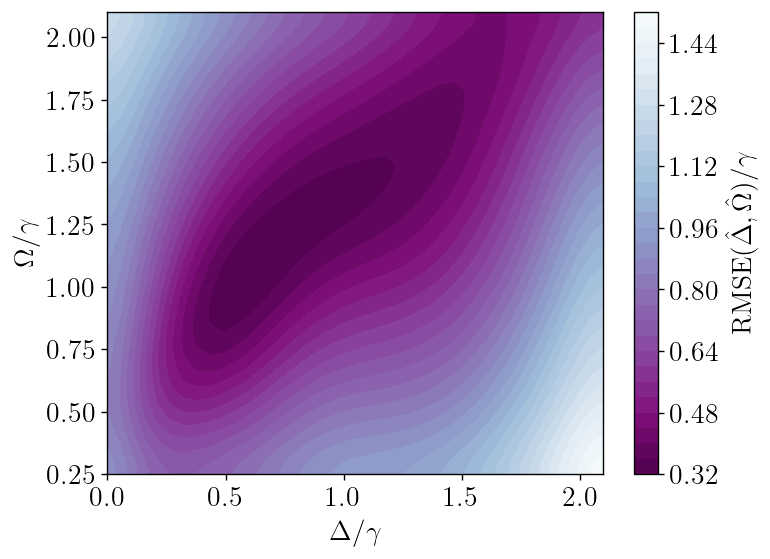

100%|██████████| 1600/1600 [00:05<00:00, 280.70it/s]


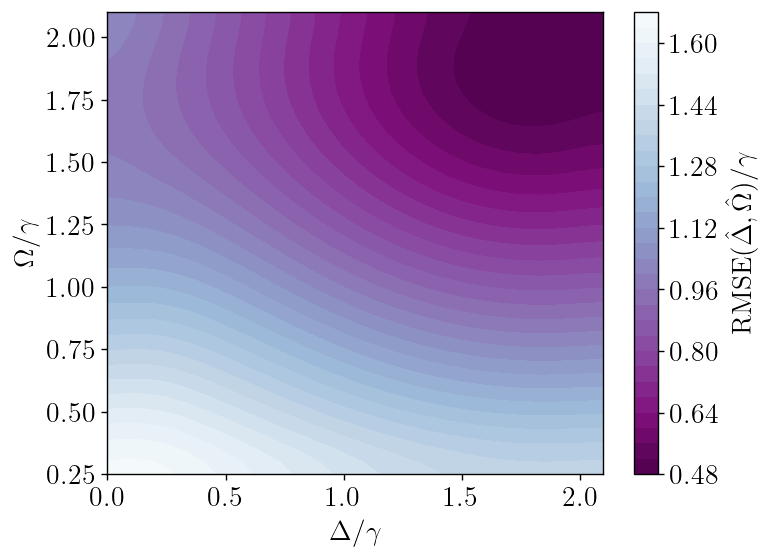

100%|██████████| 1600/1600 [00:06<00:00, 264.45it/s]


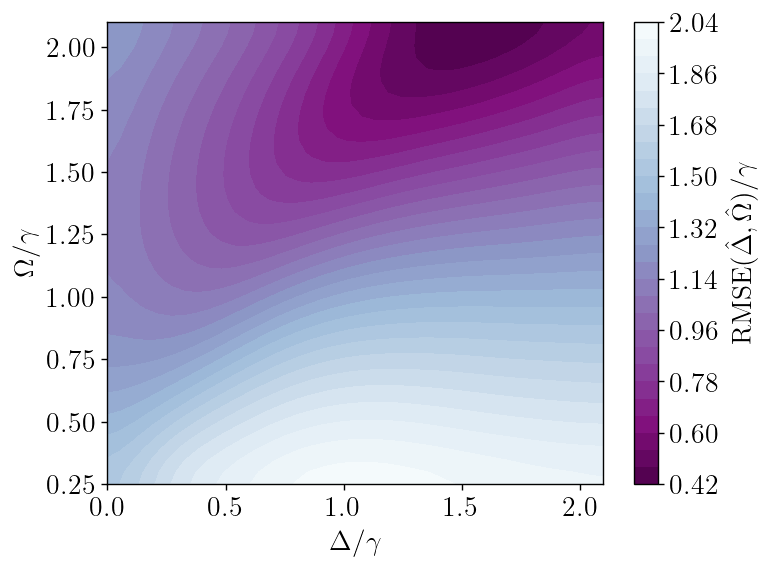

100%|██████████| 1600/1600 [00:06<00:00, 243.38it/s]


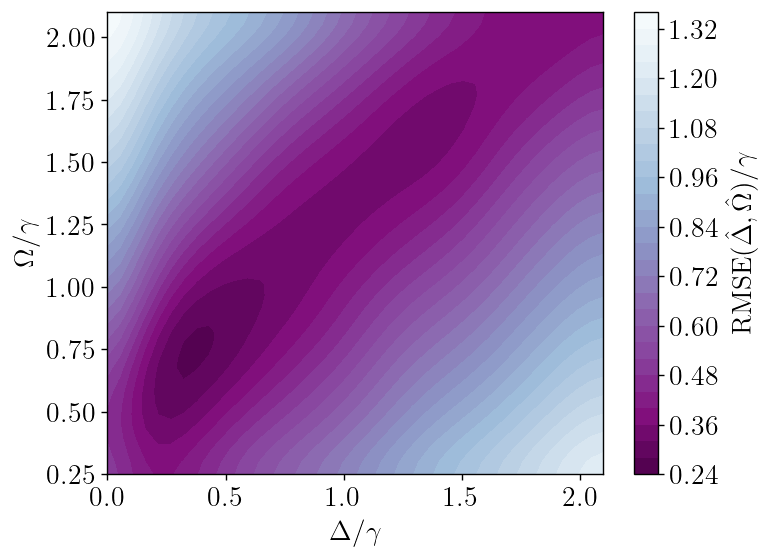

In [18]:
X_test = np.load("../test-trajectories/2D-delta-omega/validation-trajectories-2D-delta-omega-nsets-10000.npy", mmap_mode="r")
y_test = np.load("../test-trajectories/2D-delta-omega/validation-deltas-2D-delta-omega-nsets-10000.npy")

parent_run_id = "edda661d9f0544a5984928e0efee3147"
child_runs_df = mlflow.search_runs(
    filter_string=f"tags.mlflow.parentRunId = '{parent_run_id}'"
)

for index, row in child_runs_df.iterrows():
    run_id = row.run_id
    try:
        selected_model = mlflow.pytorch.load_model(model_uri=f"runs:/{run_id}/torch_model")
    except:
        continue
    # if model was logged while on gpu it will be loaded back onto gpu and will error out if GPU is not available
    selected_model = selected_model.to(device)

    selected_model.eval()
    rmse_loss = RMSELoss()

    with no_grad():
        rmses = []
        error_fn = RMSELoss()
        # loop over all 1,600 detuning-rabi freq pairs
        for i in tqdm(range(1600)):
            num_trajs = 1000
            batch_of_trajs = torch.tensor(X_test[i][:num_trajs]).to(device=device, dtype=torch.float32)
            batch_output = selected_model(batch_of_trajs)
            label = torch.tensor(y_test[i]).to(device=device, dtype=torch.float32)
            repeated_labels = repeat_interleave(label, repeats=batch_output.shape[0]).reshape(-1, 2)
            error = error_fn(batch_output, repeated_labels)
            rmses.append(error.cpu().numpy())



    x = np.sort(np.unique(y_test[:, 0])) # x axis is delta  #np.linspace(-3, 3, 200)
    y = np.sort(np.unique(y_test[:, 1])) # y axis is omega #np.linspace(-3, 3, 200)
    X, Y = np.meshgrid(x, y)
    Z = np.array(rmses).reshape(40,40) # there are 40x40=1,600 labels (detuning-rabi freq pairs)
    Z = gaussian_filter(Z, sigma=2)

    plt.figure()
    cs = plt.contourf(
        X, Y, Z,
        levels=30,
        cmap=plt.get_cmap('BuPu').reversed(),
        # vmax=0.4,
        # vmin=0.1
    )
    plt.colorbar(cs, label=r"$\textrm{RMSE}(\hat{\Delta}, \hat{\Omega})/\gamma$")
    plt.xlabel(r"$\Delta/\gamma$")
    plt.ylabel(r"$\Omega/\gamma$")
    fig = plt.gcf()
    plt.show()